In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ml_cardio.data.data_loader import load_dataset

In [4]:
df = load_dataset()

In [5]:
df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [7]:
df.describe()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [8]:
print("Columns:", df.columns.tolist())

Columns: ['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']


In [9]:
TARGET = "cardio"

df["age_years"] = df["age"] / 365.25            
df["bmi"] = df["weight"] / (df["height"] / 100) ** 2

numerical = ["age_years", "height", "weight", "bmi", "ap_hi", "ap_lo"]
binary    = ["gender", "smoke", "alco", "active"]
ordinal   = ["cholesterol", "gluc"]

In [10]:
print("Shape:", df.shape)
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows (ignoring id):", df.drop(columns="id").duplicated().sum())
print("\nConstant columns:", [c for c in df.columns if df[c].nunique() == 1])


Shape: (70000, 15)

Missing values:
 id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
age_years      0
bmi            0
dtype: int64

Duplicate rows (ignoring id): 24

Constant columns: []


In [11]:
checks = {
    "ap_hi <= 0 or > 250":     (df.ap_hi <= 0) | (df.ap_hi > 250),
    "ap_lo <= 0 or > 150":     (df.ap_lo <= 0) | (df.ap_lo > 150),
    "ap_lo >= ap_hi":          df.ap_lo >= df.ap_hi,
    "height < 120 or > 220":   (df.height < 120) | (df.height > 220),
    "weight < 30 or > 200":    (df.weight < 30) | (df.weight > 200),
    "bmi < 12 or > 60":        (df.bmi < 12) | (df.bmi > 60),
    "age < 18 years":          df.age_years < 18,
}
quality = pd.DataFrame({k: [v.sum(), round(100 * v.mean(), 2)] for k, v in checks.items()},
                       index=["count", "percent"]).T
print(quality)
print("Rows with at least one issue:", pd.concat(checks.values(), axis=1).any(axis=1).sum())

                        count  percent
ap_hi <= 0 or > 250      47.0     0.07
ap_lo <= 0 or > 150     997.0     1.42
ap_lo >= ap_hi         1236.0     1.77
height < 120 or > 220    53.0     0.08
weight < 30 or > 200      7.0     0.01
bmi < 12 or > 60         74.0     0.11
age < 18 years            0.0     0.00
Rows with at least one issue: 1378


In [12]:
for c in binary + ordinal + [TARGET]:
    print(c, sorted(df[c].unique()))


gender [np.int64(1), np.int64(2)]
smoke [np.int64(0), np.int64(1)]
alco [np.int64(0), np.int64(1)]
active [np.int64(0), np.int64(1)]
cholesterol [np.int64(1), np.int64(2), np.int64(3)]
gluc [np.int64(1), np.int64(2), np.int64(3)]
cardio [np.int64(0), np.int64(1)]


In [13]:
q1, q3 = df[numerical].quantile(.25), df[numerical].quantile(.75)
iqr = q3 - q1
outliers = ((df[numerical] < q1 - 1.5 * iqr) | (df[numerical] > q3 + 1.5 * iqr)).sum()
print("\nIQR outliers:\n", outliers)



IQR outliers:
 age_years       4
height        519
weight       1819
bmi          1995
ap_hi        1435
ap_lo        4632
dtype: int64


In [14]:
df[numerical].describe().T

,count,mean,std,min,25%,50%,75%,max
age_years,70000.0,53.302850,6.754967,29.563313,48.361396,53.943874,58.390144,64.922656
height,70000.0,164.359229,8.210126,55.000000,159.000000,165.000000,170.000000,250.000000
weight,70000.0,74.205690,14.395757,10.000000,65.000000,72.000000,82.000000,200.000000
bmi,70000.0,27.556513,6.091511,3.471784,23.875115,26.374068,30.222222,298.666667
ap_hi,70000.0,128.817286,154.011419,-150.000000,120.000000,120.000000,140.000000,16020.000000
ap_lo,70000.0,96.630414,188.472530,-70.000000,80.000000,80.000000,90.000000,11000.000000


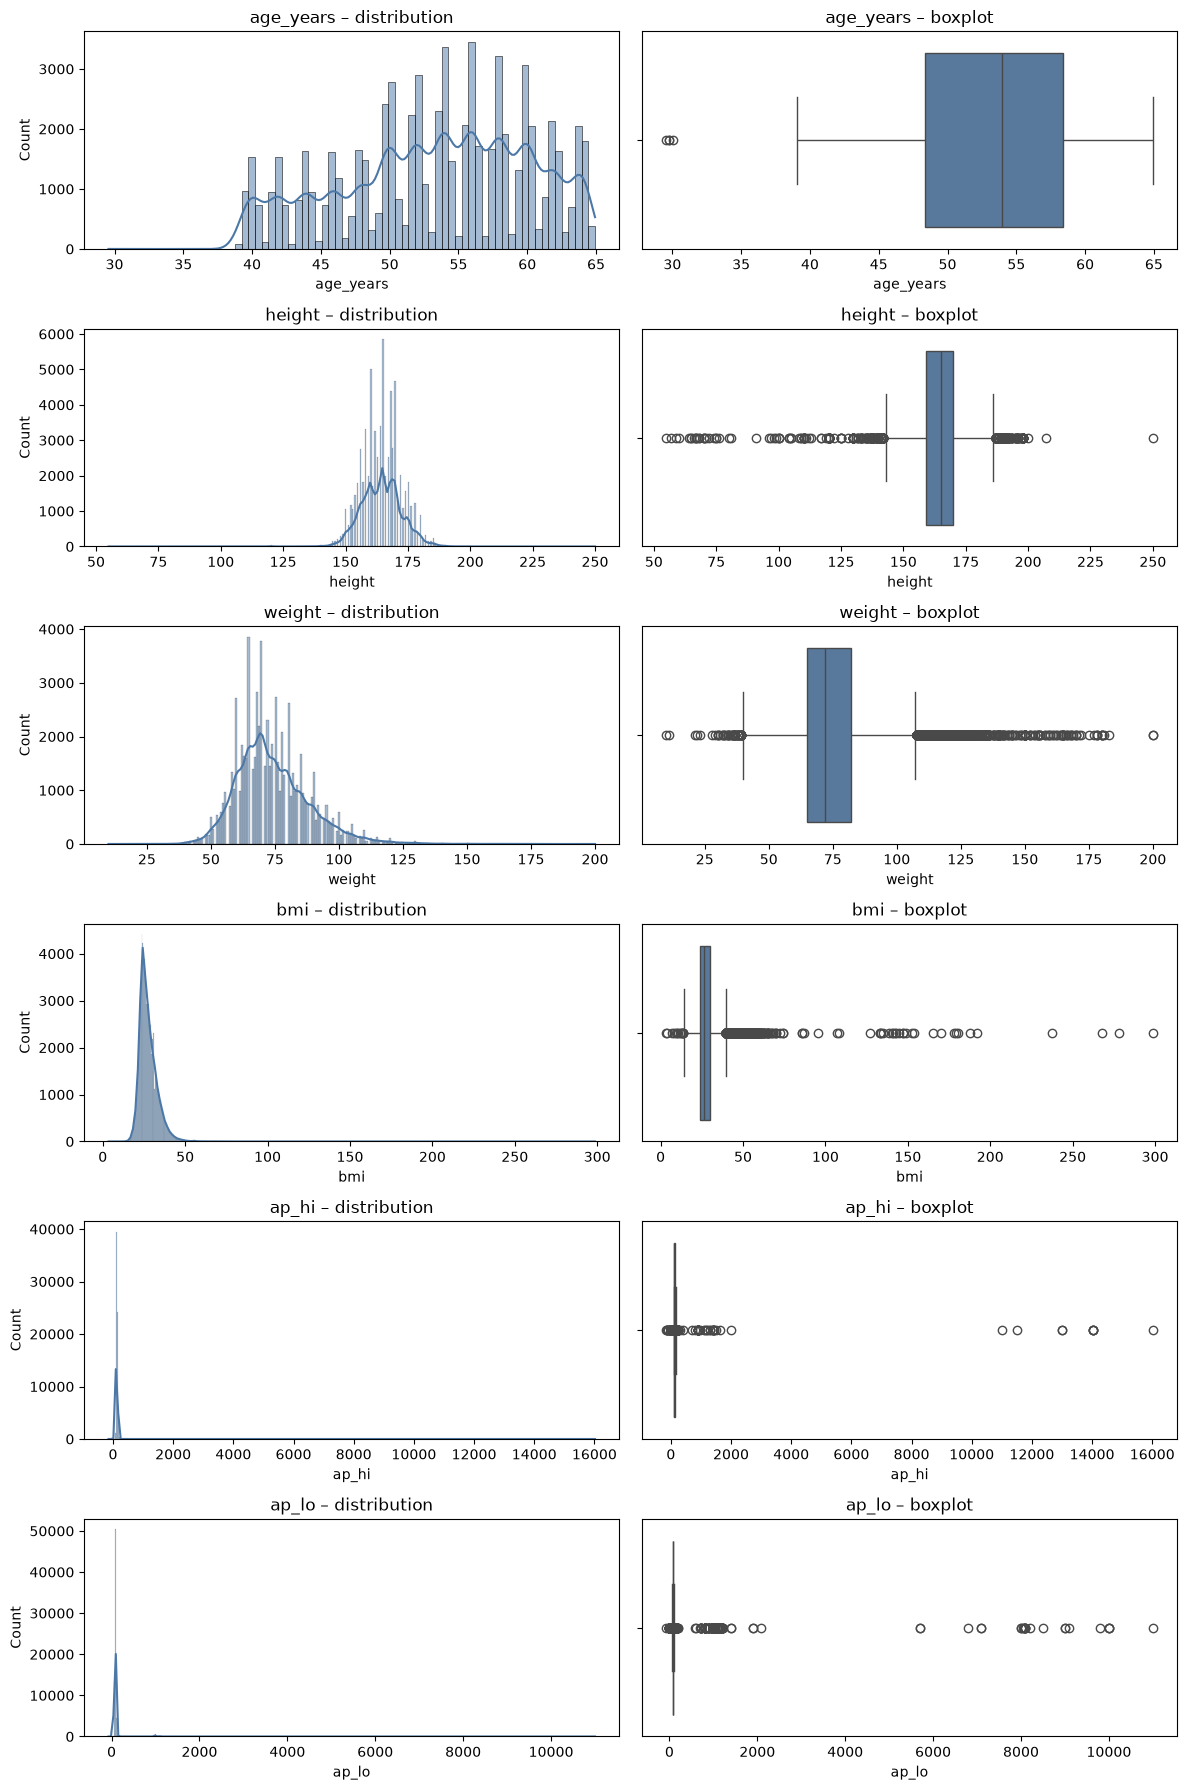

In [15]:
fig, axes = plt.subplots(len(numerical), 2, figsize=(12, 3 * len(numerical)))
for i, c in enumerate(numerical):
    sns.histplot(df[c], kde=True, ax=axes[i, 0], color="#4C78A8")
    sns.boxplot(x=df[c], ax=axes[i, 1], color="#4C78A8")
    axes[i, 0].set_title(f"{c} – distribution")
    axes[i, 1].set_title(f"{c} – boxplot")
plt.tight_layout(); plt.show()

In [16]:
print(df[numerical].skew().round(2))

age_years    -0.31
height       -0.64
weight        1.01
bmi           7.73
ap_hi        85.30
ap_lo        32.11
dtype: float64


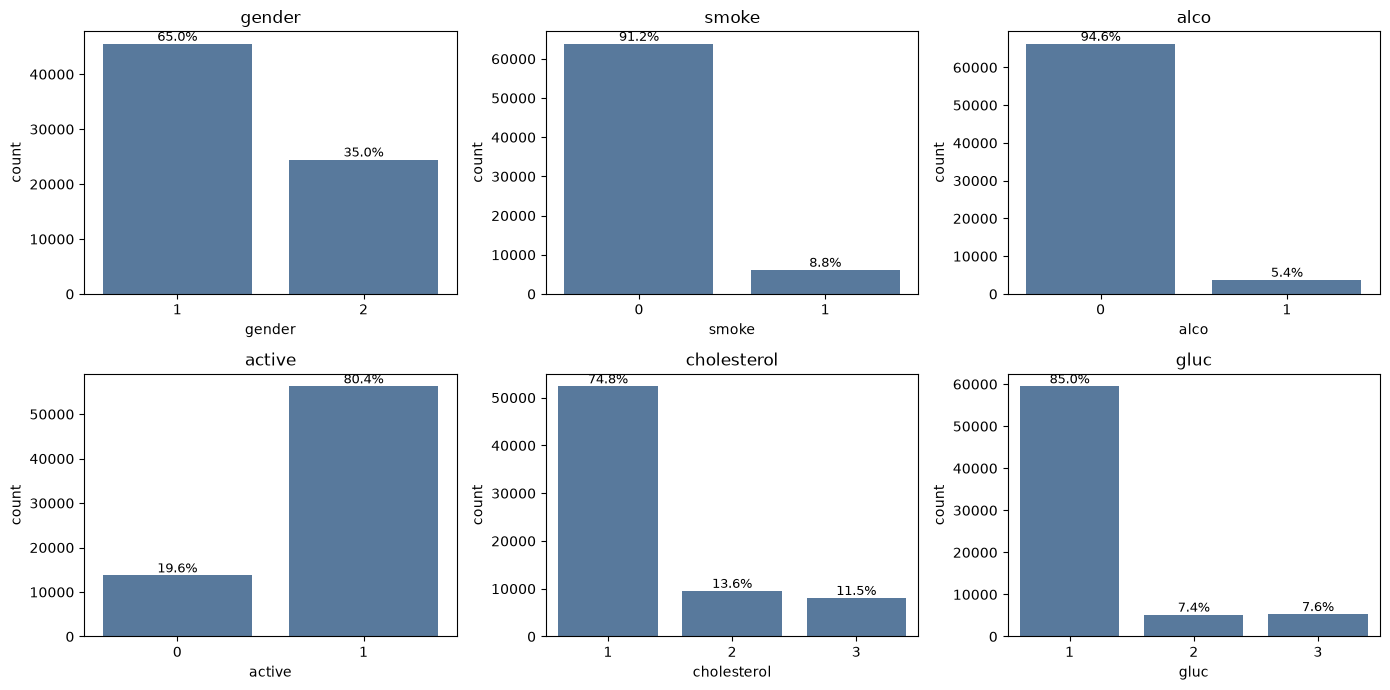

In [17]:
cats = binary + ordinal
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), cats):
    order = sorted(df[c].unique())
    sns.countplot(x=df[c], order=order, ax=ax, color="#4C78A8")
    ax.set_title(c)
    for p in ax.patches:
        ax.annotate(f"{100 * p.get_height() / len(df):.1f}%",
                    (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

cardio
0    35021
1    34979
Name: count, dtype: int64 
 cardio
0    50.03
1    49.97
Name: proportion, dtype: float64


C:\Users\MSI\AppData\Local\Temp\ipykernel_11576\1505350097.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df[TARGET], ax=ax, palette=["#4C78A8", "#E45756"])


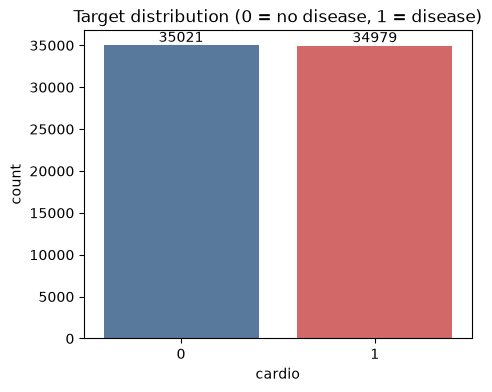

In [18]:
counts = df[TARGET].value_counts().sort_index()
print(counts, "\n", (df[TARGET].value_counts(normalize=True) * 100).round(2))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x=df[TARGET], ax=ax, palette=["#4C78A8", "#E45756"])
ax.set_title("Target distribution (0 = no disease, 1 = disease)")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.show()

In [19]:
print("Imbalance ratio:", round(counts.max() / counts.min(), 3))

Imbalance ratio: 1.001


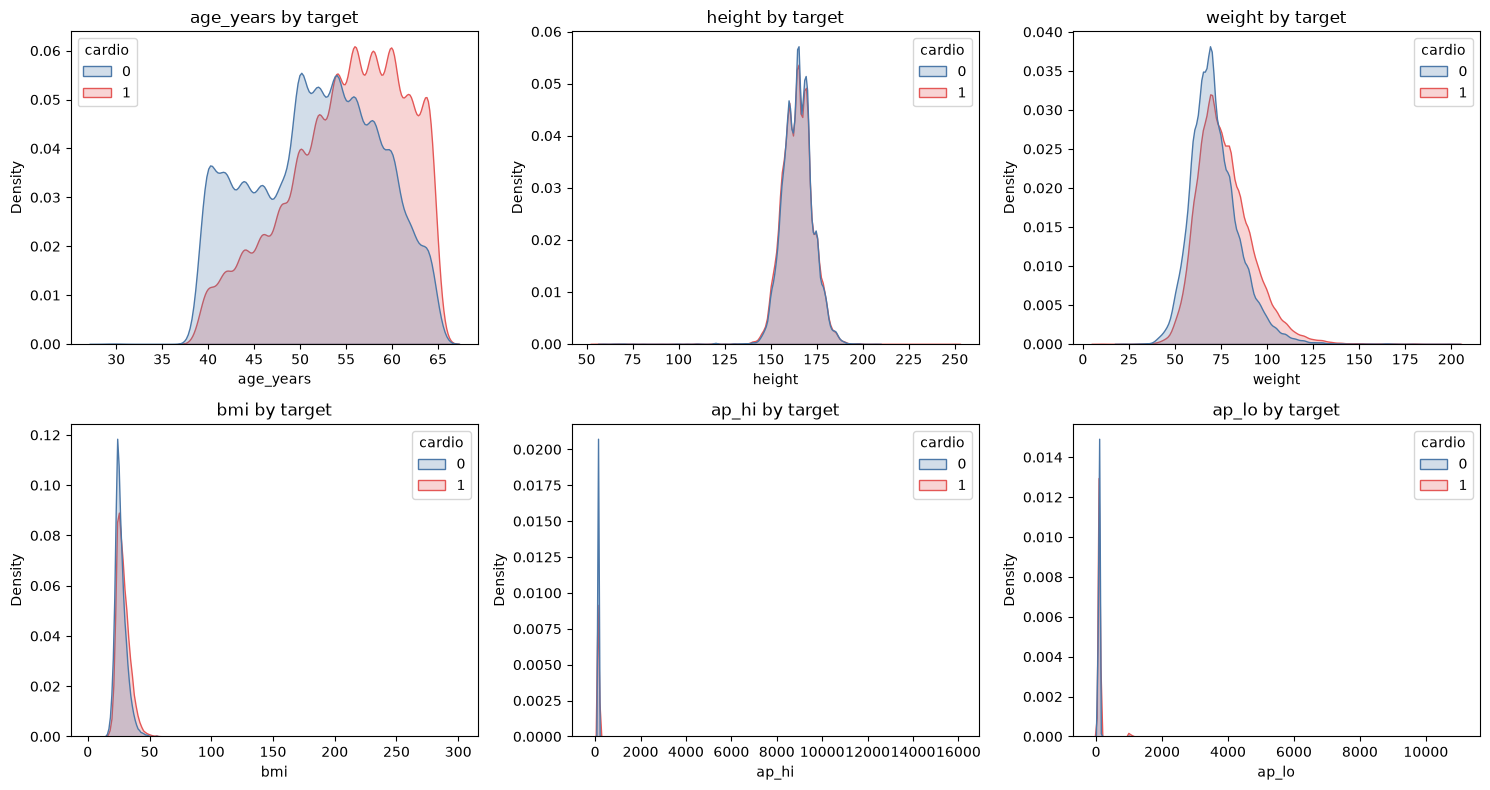

In [20]:
palette = ["#4C78A8", "#E45756"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), numerical):
    sns.kdeplot(data=df, x=c, hue=TARGET, common_norm=False, fill=True, palette=palette, ax=ax)
    ax.set_title(f"{c} by target")
plt.tight_layout(); plt.show()

C:\Users\MSI\AppData\Local\Temp\ipykernel_11576\342584134.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=TARGET, y=c, palette=palette, ax=ax)
C:\Users\MSI\AppData\Local\Temp\ipykernel_11576\342584134.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=TARGET, y=c, palette=palette, ax=ax)
C:\Users\MSI\AppData\Local\Temp\ipykernel_11576\342584134.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=TARGET, y=c, palette=palette, ax=ax)
C:\Users\MSI\AppData\Local\Temp\ipykernel_11576\342584134.py:3: FutureWar

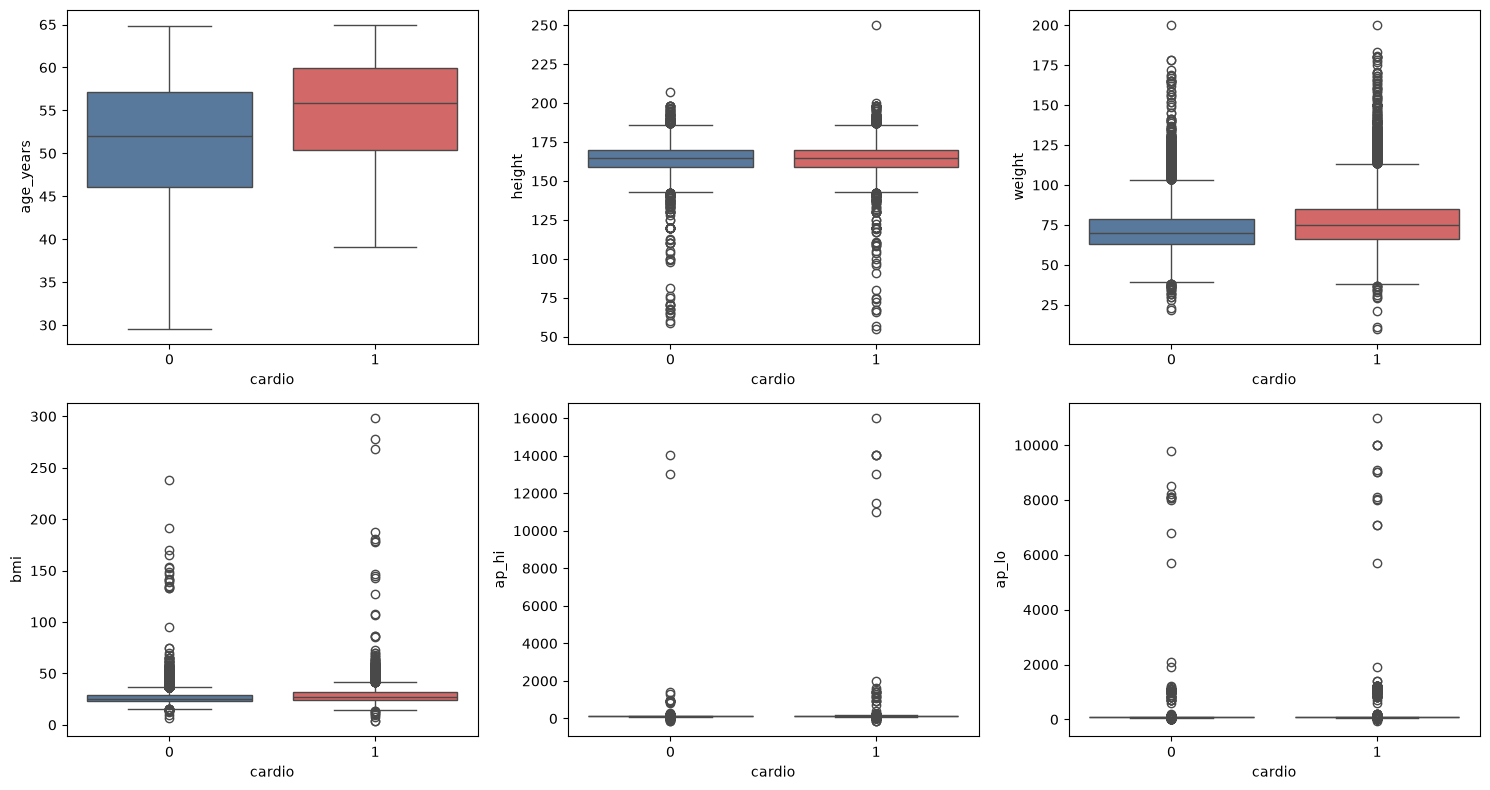

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), numerical):
    sns.boxplot(data=df, x=TARGET, y=c, palette=palette, ax=ax)
plt.tight_layout(); plt.show()

In [22]:
print(df.groupby(TARGET)[numerical].mean().round(2).T)

cardio          0       1
age_years   51.70   54.91
height     164.45  164.27
weight      71.59   76.82
bmi         26.55   28.57
ap_hi      120.43  137.21
ap_lo       84.25  109.02


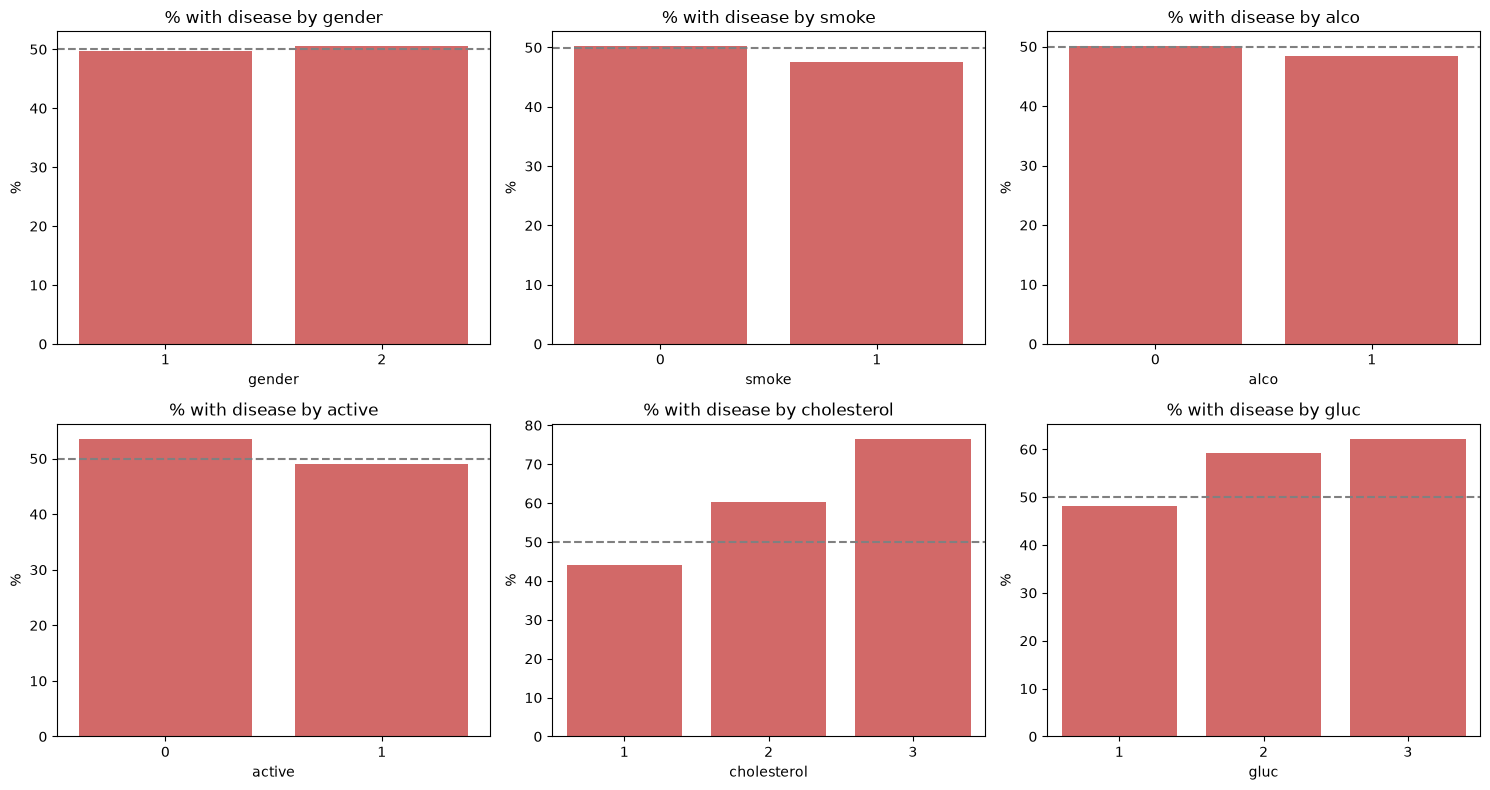

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), binary + ordinal):
    rate = df.groupby(c)[TARGET].mean() * 100
    sns.barplot(x=rate.index, y=rate.values, ax=ax, color="#E45756")
    ax.axhline(df[TARGET].mean() * 100, ls="--", color="grey")
    ax.set_title(f"% with disease by {c}"); ax.set_ylabel("%")
plt.tight_layout(); plt.show()

In [24]:
from scipy import stats
rows = []
for c in numerical:
    t, p = stats.mannwhitneyu(df.loc[df[TARGET] == 0, c], df.loc[df[TARGET] == 1, c])
    rows.append((c, "Mann-Whitney U", p))
for c in binary + ordinal:
    chi2, p, *_ = stats.chi2_contingency(pd.crosstab(df[c], df[TARGET]))
    rows.append((c, "Chi-square", p))
print(pd.DataFrame(rows, columns=["feature", "test", "p_value"]).round(4))

        feature            test  p_value
0     age_years  Mann-Whitney U   0.0000
1        height  Mann-Whitney U   0.0011
2        weight  Mann-Whitney U   0.0000
3           bmi  Mann-Whitney U   0.0000
4         ap_hi  Mann-Whitney U   0.0000
5         ap_lo  Mann-Whitney U   0.0000
6        gender      Chi-square   0.0325
7         smoke      Chi-square   0.0000
8          alco      Chi-square   0.0545
9        active      Chi-square   0.0000
10  cholesterol      Chi-square   0.0000
11         gluc      Chi-square   0.0000


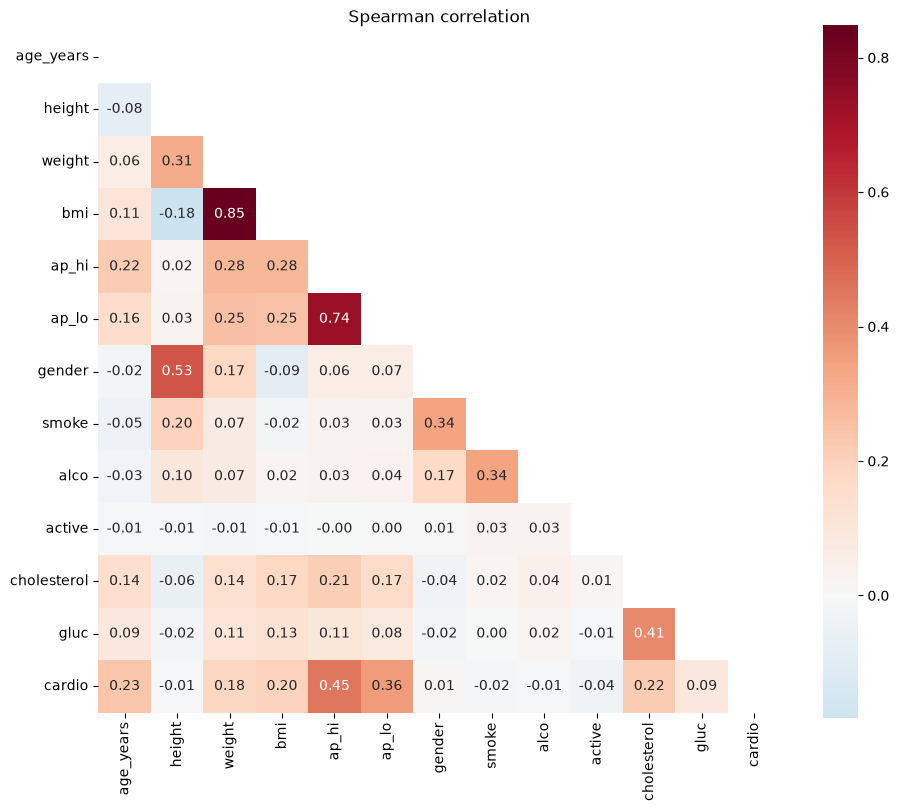

In [25]:
corr = df[numerical + binary + ordinal + [TARGET]].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True)
plt.title("Spearman correlation"); plt.show()


In [26]:
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3))


ap_hi          0.452
ap_lo          0.363
age_years      0.234
cholesterol    0.215
bmi            0.199
weight         0.183
gluc           0.091
active        -0.036
smoke         -0.015
height        -0.012
gender         0.008
alco          -0.007
Name: cardio, dtype: float64


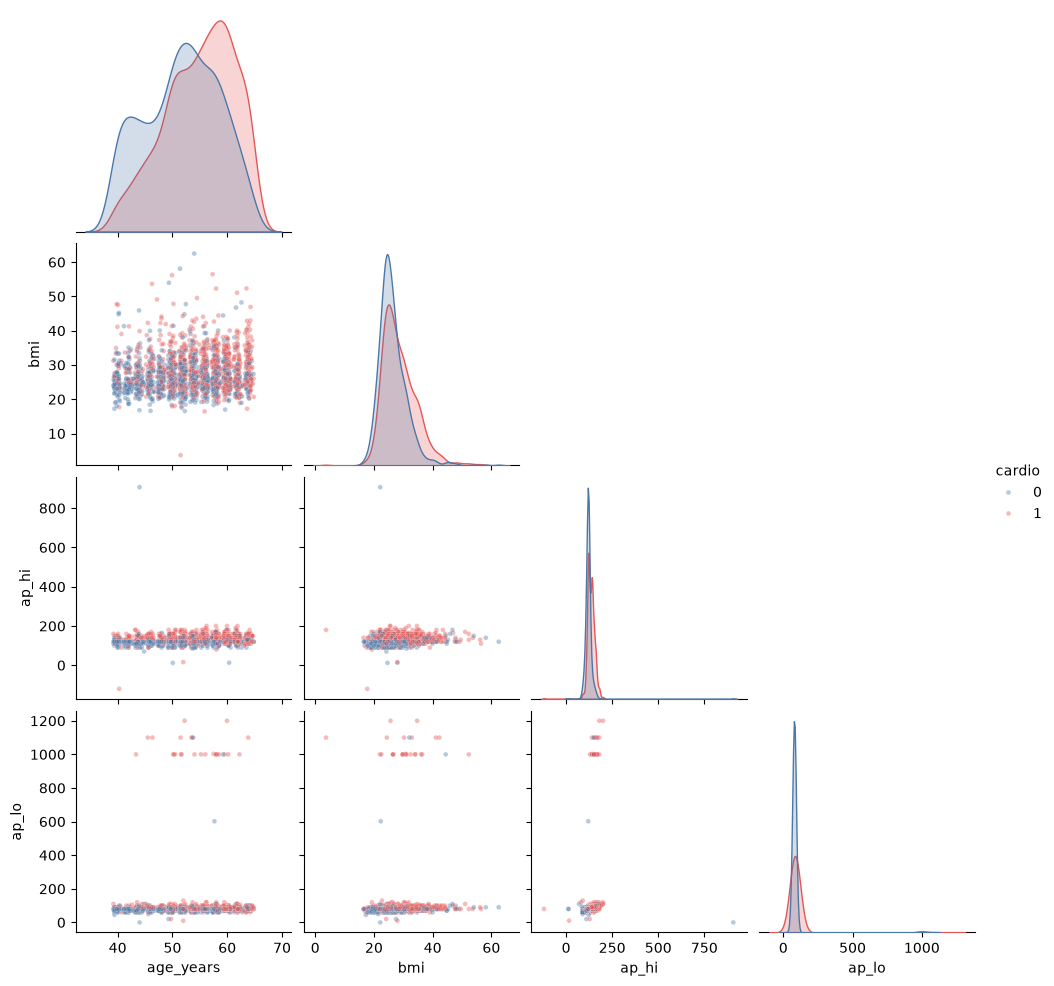

In [28]:
# Pairwise relationships on a sample
sns.pairplot(df.sample(2000, random_state=42), vars=["age_years", "bmi", "ap_hi", "ap_lo"],
             hue=TARGET, palette=["#4C78A8", "#E45756"], corner=True, plot_kws={"alpha": .4, "s": 12})
plt.show()

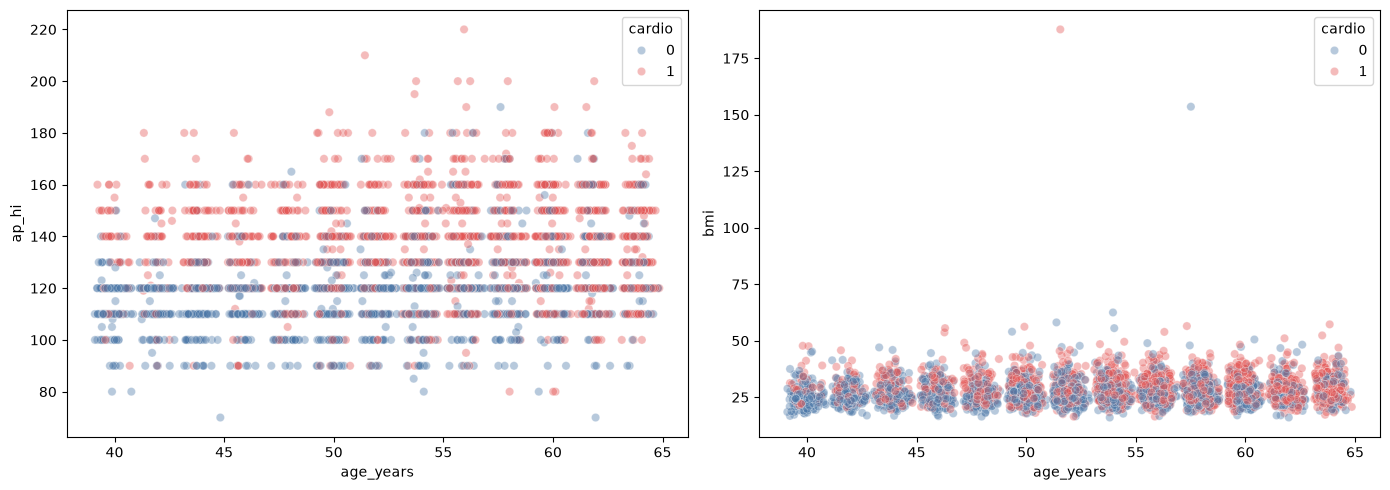

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
s = df.sample(5000, random_state=42)
s = s[(s.ap_hi.between(70, 250)) & (s.ap_lo.between(40, 150))]
sns.scatterplot(data=s, x="age_years", y="ap_hi", hue=TARGET, palette=["#4C78A8", "#E45756"], alpha=.4, ax=axes[0])
sns.scatterplot(data=s, x="age_years", y="bmi", hue=TARGET, palette=["#4C78A8", "#E45756"], alpha=.4, ax=axes[1])
plt.tight_layout(); plt.show()


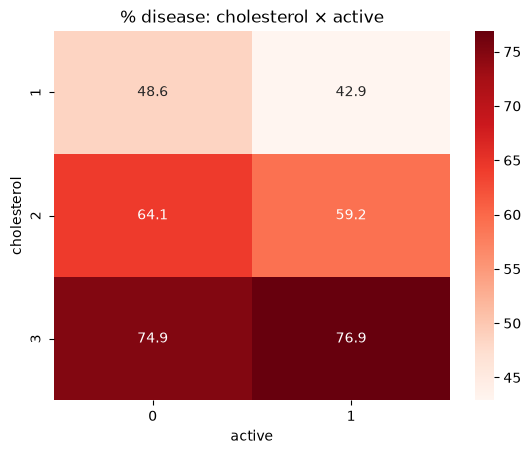

In [30]:
pivot = df.pivot_table(index="cholesterol", columns="active", values=TARGET, aggfunc="mean") * 100
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds"); plt.title("% disease: cholesterol × active"); plt.show()